# 03 · Extensión experimental: ¿qué pasa si los nombres vienen abreviados?

**Condición modificada (una sola):** el porcentaje de autorías en que el nombre de pila aparece **solo con iniciales** ("Wang, J." en vez de "Wang, Jian-Cheng").

**Por qué esta condición.** Es el corazón del problema del artículo: ADS abrevia la mayoría de los nombres y por eso la desambiguación es necesaria. También es relevante para el trabajo de grado: las fuentes que se van a integrar (DSpace, RePEc, OpenAlex, Crossref) difieren justamente en cuánto abrevian los nombres (las listas de referencias y muchos metadatos solo traen iniciales).

**Qué se mantiene fijo:** los mismos autores, bloques, afiliaciones, textos, coautores y años; la misma partición; el mismo algoritmo y los mismos hiperparámetros (RF de referencia del notebook 02, accuracy, {0:5,1:1}). Para que solo cambie la condición se usan **números aleatorios comunes**: cada autoría tiene un número fijo `u_abbr` y se abrevia si `u_abbr < p`; al subir `p`, las autorías abreviadas del escenario base siguen abreviadas y se agregan otras.

**Escenarios:** p = 0 %, 30 %, **60 % (base)**, 80 %, 100 % de nombres abreviados. Se compara contra la regla de Milojević, que solo usa nombres.

**Hipótesis:** la regla basada en iniciales no cambia mucho (ya usa solo iniciales), pero el clasificador pierde las variables de nombre completo y, sobre todo en los bloques homónimos, debe apoyarse en coautores, afiliación y contenido; se espera una caída moderada de la precisión BCubed (más fusiones).

In [1]:
import json
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C, features as F, models as M, pipeline as PP, plots as PL, simulation as S

PL.set_style()
pd.set_option("display.width", 180)

df0 = pd.read_csv(C.DATA / "simulated_authorships.csv", keep_default_na=False)
pairs0 = F.load_or_build_pairs(df0, "base")
ref = json.load(open(C.RESULTS / "02_modelo_referencia.json"))
print("Modelo:", ref)

Modelo: {'algorithm': 'Random Forest', 'ratio': '{0:5,1:1}', 'scoring': 'accuracy', 'params': {'n_estimators': 30, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'gini'}}


Para separar el efecto de la condición del azar del propio procedimiento (submuestreo, bosque aleatorio y label propagation), cada escenario se repite con **3 semillas** y se reporta la media y la desviación estándar.

In [2]:
SCENARIOS = [0.0, 0.3, C.SIM["p_abbreviated"], 0.8, 1.0]
SEEDS = [2021, 7, 99]
rows, block_rows = [], []
for p in SCENARIOS:
    df = S.render_names(df0, p)                         # solo cambia el nombre observado
    names = F.all_pairs(df, names_only=True)            # se recalculan solo las variables de nombre
    assert (names.i.values == pairs0.i.values).all() and (names.j.values == pairs0.j.values).all()
    pairs = pairs0.copy()
    pairs[F.NAME_FEATURES] = names[F.NAME_FEATURES].values
    train = pairs[pairs.subset == "train"].reset_index(drop=True)
    test = pairs[pairs.subset != "train"].reset_index(drop=True)
    pct_abbr = (df.first_part.str.len() == 1).mean()
    rule = PP.evaluate_rule(df)                         # la regla es determinista
    for subset, m in rule["subsets"].items():
        rows.append({"p_abreviado": p, "pct_real_abreviado": pct_abbr, "metodo": "Reglas (Milojević)",
                     "seed": 0, "subset": subset, **m})
    for seed in SEEDS:
        sel = M.downsample(train.y.to_numpy(), C.RATIOS[ref["ratio"]], seed)
        model = M.make_model(ref["algorithm"], ref["params"], seed).fit(
            train.loc[sel, F.FEATURES].to_numpy(np.float32), train.y.to_numpy()[sel])
        ev = PP.evaluate_model(model, df, test, F.FEATURES, seed=seed)
        imp = pd.Series(model.feature_importances_, index=F.FEATURES)
        for subset, m in ev["subsets"].items():
            rows.append({"p_abreviado": p, "pct_real_abreviado": pct_abbr, "metodo": "Random Forest", "seed": seed,
                         "subset": subset, **m, "importancia_nombre": imp[F.NAME_FEATURES].sum()})
        b = ev["blocks"]
        for _, r in b[b.subset == "test_large"].iterrows():
            block_rows.append({"p_abreviado": p, "seed": seed, **r.to_dict()})
    rf = pd.DataFrame(rows).query("metodo == 'Random Forest' and subset == 'todos' and p_abreviado == @p")
    print(f"p = {p:.0%}: RF F1 macro (todos) = {rf.macro_b3f.mean():.3f} ± {rf.macro_b3f.std():.3f} · "
          f"regla = {rule['subsets']['todos']['macro_b3f']:.3f}")
runs = pd.DataFrame(rows)
runs.round(4).to_csv(C.RESULTS / "03_extension_corridas.csv", index=False)
metrics = ["macro_b3p", "macro_b3r", "macro_b3f", "micro_b3f", "pred_clusters", "true_clusters", "importancia_nombre"]
res = runs.groupby(["metodo", "subset", "p_abreviado"])[metrics].agg(["mean", "std"])
res.columns = [f"{a}_{b}" for a, b in res.columns]
res = res.reset_index()
res.round(4).to_csv(C.RESULTS / "03_extension_abreviacion.csv", index=False)
blocks = pd.DataFrame(block_rows)
blocks.round(4).to_csv(C.RESULTS / "03_extension_bloques_grandes.csv", index=False)

p = 0%: RF F1 macro (todos) = 0.864 ± 0.014 · regla = 0.765


p = 30%: RF F1 macro (todos) = 0.869 ± 0.004 · regla = 0.776


p = 60%: RF F1 macro (todos) = 0.872 ± 0.006 · regla = 0.789


p = 80%: RF F1 macro (todos) = 0.876 ± 0.002 · regla = 0.797


p = 100%: RF F1 macro (todos) = 0.888 ± 0.002 · regla = 0.808


## Resultados

In [3]:
cols = ["macro_b3p_mean", "macro_b3r_mean", "macro_b3f_mean", "macro_b3f_std", "pred_clusters_mean", "true_clusters_mean"]
res[res.subset.isin(["todos", "grandes"])].set_index(["metodo", "subset", "p_abreviado"])[cols].round(3)

macro_b3p_mean  macro_b3r_mean  macro_b3f_mean  macro_b3f_std  pred_clusters_mean  true_clusters_mean
metodo             subset  p_abreviado                                                                                                       
Random Forest      grandes 0.0                   0.713           0.940           0.811          0.020              17.000              39.667
                           0.3                   0.728           0.946           0.823          0.006              16.333              39.667
                           0.6                   0.741           0.948           0.831          0.009              16.778              39.667
                           0.8                   0.749           0.946           0.836          0.003              16.889              39.667
                           1.0                   0.770           0.959           0.854          0.002              18.056              39.667
                   todos   0.0                   0.788           0.956           0.864          0.014               4.684               8.333
                           0.3                   0.795           0.959           0.869          0.004               4.470               8.333
                           0.6                   0.800           0.960           0.872          0.006               4.496               8.333
                           0.8                   0.806           0.959           0.876          0.002               4.556               8.333
                           1.0                   0.821           0.968           0.888          0.002               4.709               8.333
Reglas (Milojević) grandes 0.0                   0.626           0.834           0.715            NaN               9.833              39.667
                           0.3                   0.634           0.857           0.729            NaN               9.833              39.667
                           0.6                   0.645           0.883           0.745            NaN               9.833              39.667
                           0.8                   0.652           0.898           0.755            NaN               9.833              39.667
                           1.0                   0.661           0.921           0.770            NaN               9.833              39.667
                   todos   0.0                   0.692           0.856           0.765            NaN               2.821               8.333
                           0.3                   0.698           0.873           0.776            NaN               2.821               8.333
                           0.6                   0.706           0.893           0.789            NaN               2.821               8.333
                           0.8                   0.712           0.906           0.797            NaN               2.821               8.333
                           1.0                   0.719           0.924           0.808            NaN               2.821               8.333

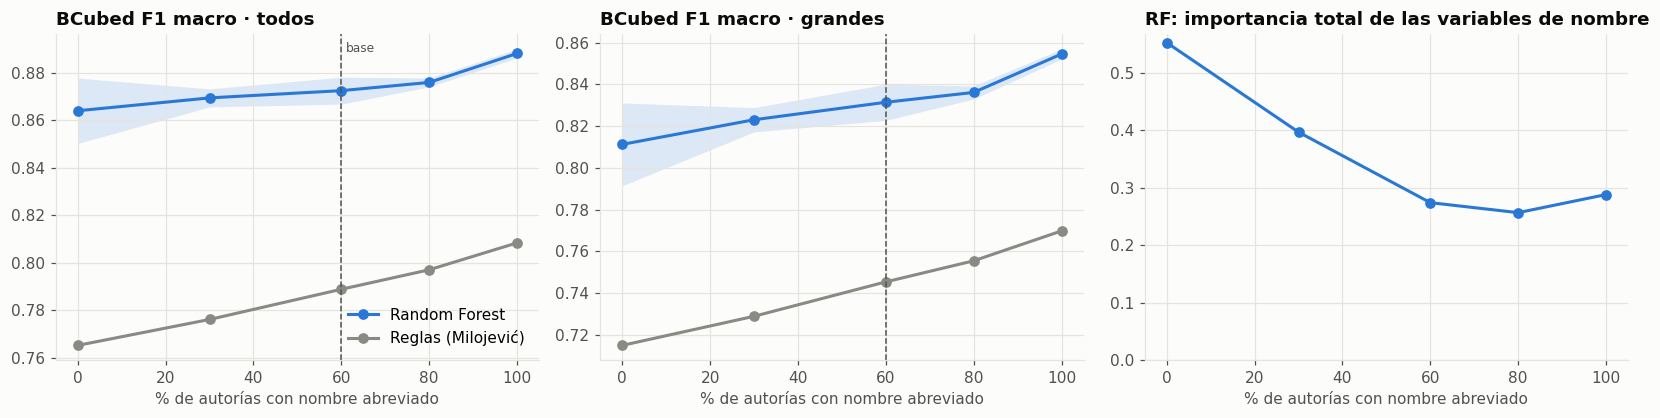

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
x = np.array([100 * p for p in SCENARIOS])
for ax, subset in zip(axes[:2], ["todos", "grandes"]):
    for metodo, color in (("Random Forest", PL.PALETTE[0]), ("Reglas (Milojević)", "#8a8984")):
        s = res[(res.subset == subset) & (res.metodo == metodo)].sort_values("p_abreviado")
        ax.plot(x, s.macro_b3f_mean, marker="o", lw=2, ms=6, color=color, label=metodo)
        if metodo == "Random Forest":
            sd = s.macro_b3f_std.fillna(0).values
            ax.fill_between(x, s.macro_b3f_mean - sd, s.macro_b3f_mean + sd, color=color, alpha=0.15, lw=0)
    ax.axvline(100 * C.SIM["p_abbreviated"], color=PL.MUTED, lw=1, ls="--")
    ax.set_title(f"BCubed F1 macro · {subset}"); ax.set_xlabel("% de autorías con nombre abreviado")
axes[0].legend(loc="lower right")
axes[0].annotate("base", (100 * C.SIM["p_abbreviated"], axes[0].get_ylim()[1]), xytext=(3, -12),
                 textcoords="offset points", fontsize=8, color=PL.MUTED)
s = res[(res.subset == "todos") & (res.metodo == "Random Forest")].sort_values("p_abreviado")
axes[2].plot(x, s.importancia_nombre_mean, marker="o", lw=2, ms=6, color=PL.PALETTE[0])
axes[2].set_ylim(0, None)
axes[2].set_title("RF: importancia total de las variables de nombre"); axes[2].set_xlabel("% de autorías con nombre abreviado")
fig.tight_layout(); PL.save(fig, "03_extension_abreviacion.png")

p_abreviado,0.0,0.3,0.6,0.8,1.0
block,,,,,
binzel.r,1.000,1.000,1.000,1.000,1.000
lee.j,0.640,0.521,0.552,0.544,0.573
zhang.y,0.684,0.688,0.738,0.753,0.760
wang.j,0.635,0.735,0.729,0.742,0.803
russell.c,0.998,0.998,1.000,0.998,0.998
chen.y,0.722,0.803,0.797,0.814,0.844


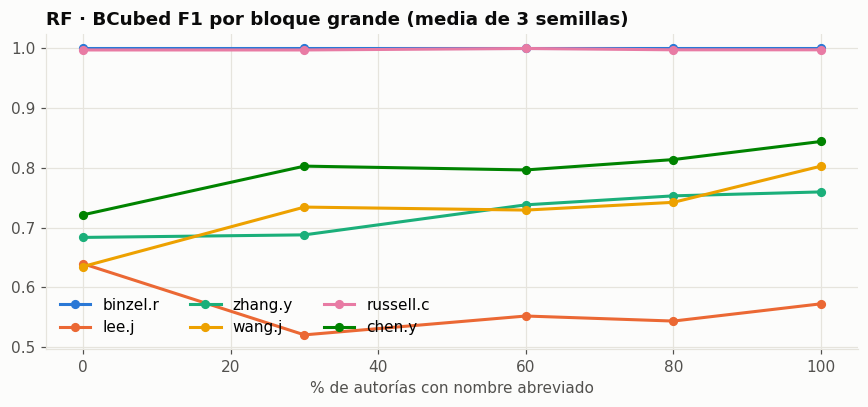

In [5]:
lg = blocks.groupby(["block", "p_abreviado"]).b3f.mean().unstack().loc[[b for b, *_ in C.LARGE_BLOCKS]]
lg.round(3).to_csv(C.RESULTS / "03_extension_f1_por_bloque_grande.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
for (b, row), c in zip(lg.iterrows(), PL.PALETTE):
    ax.plot(x, row.values, marker="o", lw=2, ms=5, color=c, label=b)
ax.set_title("RF · BCubed F1 por bloque grande (media de 3 semillas)"); ax.set_xlabel("% de autorías con nombre abreviado")
ax.legend(ncols=3, loc="lower left")
fig.tight_layout(); PL.save(fig, "03_extension_por_bloque.png")
lg.round(3)

### Contraste principal: base (60 %) frente a todos los nombres abreviados (100 %)

In [6]:
base, ext = C.SIM["p_abbreviated"], 1.0
d = res[res.p_abreviado.isin([base, ext])].pivot_table(index=["metodo", "subset"], columns="p_abreviado",
                                                       values=["macro_b3p_mean", "macro_b3r_mean", "macro_b3f_mean"])
delta = pd.DataFrame({m: d[(m, ext)] - d[(m, base)] for m in ["macro_b3p_mean", "macro_b3r_mean", "macro_b3f_mean"]})
delta.columns = ["Δ precisión", "Δ recall", "Δ F1"]
delta.round(3).to_csv(C.RESULTS / "03_delta_base_vs_100.csv")
delta.round(3)

Δ precisión  Δ recall   Δ F1
metodo             subset                                  
Random Forest      aleatorios       -0.001    -0.002 -0.002
                   grandes           0.030     0.011  0.023
                   todos             0.021     0.008  0.016
Reglas (Milojević) aleatorios        0.003     0.010  0.006
                   grandes           0.016     0.039  0.024
                   todos             0.012     0.030  0.020

### ¿Por qué más nombres completos no ayudan aquí? Consistencia de la firma de un mismo autor

In [7]:
cons = []
for p in SCENARIOS:
    df = S.render_names(df0, p)
    t = df[df.subset != "train"]
    g = t.groupby("author_id").signature.nunique()
    cons.append({"p_abreviado": p, "firmas distintas por autor (media)": g.mean(),
                 "% autores con una sola firma": (g == 1).mean()})
cons = pd.DataFrame(cons)
cons.round(3).to_csv(C.RESULTS / "03_consistencia_firmas.csv", index=False)
cons.round(3)

,p_abreviado,firmas distintas por autor (media),% autores con una sola firma
0,0.0,2.172,0.403
1,0.3,2.692,0.182
2,0.6,2.480,0.206
3,0.8,2.135,0.335
4,1.0,1.222,0.778
